# Building Energy Efficiency - Regression Project
## Notebook 3: Final Testing -> Deployment Preparation -> Monitoring

**Covers ML process steps 8 (Model Testing and Deployment) and 10 (Monitoring and Maintenance).**

Until now the **test set was locked away**. In this notebook we open it **once** to measure how the chosen models perform on buildings they have never seen. This is the number we report as our real performance.

> **Why is the test set special?** Every decision in Notebooks 1-2 (which model, which settings) was made by looking at validation data, which makes validation scores slightly *optimistic*. The test set was never used for any decision, so its score is an honest estimate.

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_predict, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from inference import add_engineered, predict_loads, nearest_shape, TARGETS, RAW, GEOMETRY, ENGINEERED
import monitor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 220)

SEED = 42
NJ = os.cpu_count()
FIG, MODELS, S = Path("figures"), Path("models"), Path("data/splits")
HEAT, COOL = "#EC4259", "#2A7CBD"
COLORS = {"heating_load": HEAT, "cooling_load": COOL}
TARGET_R2, TARGET_RMSE = 0.95, 2.0

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def lean(pipe):
    """Run the model on one thread. On a tiny dataset, many XGBoost threads spend their time waiting for each other
    (we measured 17-40 s per fit with 12 threads against 0.2-0.5 s with 1 thread), and one thread is also the right
    setting for answering a single web request quickly."""
    if "n_jobs" in pipe.named_steps["model"].get_params():
        pipe.set_params(model__n_jobs=1)
    return pipe

train, val, test = (pd.read_csv(S / f"{n}.csv") for n in ["train", "val", "test"])
cfg = json.load(open(MODELS / "config.json"))
FEATS = cfg[TARGETS[0]]["features"]
fitted = {t: lean(joblib.load(MODELS / f"{t}_fitted_on_train.joblib")) for t in TARGETS}
shapes = pd.read_csv(S / "shape_table.csv")
rmse = lambda y, p: float(np.sqrt(mean_squared_error(y, p)))
for t in TARGETS:
    print(f"{t:>13}: {cfg[t]['model']}  (90% error band from training CV: +/- {cfg[t]['error_band_90']:.2f})")
print("test buildings:", len(test))

 heating_load: XGBoost (Optuna)  (90% error band from training CV: +/- 0.66)
 cooling_load: XGBoost (Optuna)  (90% error band from training CV: +/- 1.77)
test buildings: 116


---
# Step 8.1 - Final evaluation on the test set

We evaluate the **exact pipelines validated in Notebook 2** (trained on the training set only). Each score comes with a **95% confidence interval** from **bootstrapping**: we re-draw the test buildings *with replacement* 2,000 times and recompute the score each time. The spread tells us how much a score could wobble just from which buildings landed in the test set.

In [2]:
rng = np.random.default_rng(SEED)

def boot_ci(y, p, n=2000):
    idx = rng.integers(0, len(y), size=(n, len(y)))
    yb, pb = y[idx], p[idx]
    rm = np.sqrt(((yb - pb) ** 2).mean(axis=1))
    r2 = 1 - ((yb - pb) ** 2).sum(axis=1) / ((yb - yb.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    return np.percentile(rm, [2.5, 97.5]), np.percentile(r2, [2.5, 97.5])

rows, preds = [], {}
for t in TARGETS:
    y_te, y_va = test[t].values, val[t].values
    p_te, p_va = fitted[t].predict(test[FEATS]), fitted[t].predict(val[FEATS])
    preds[t] = p_te
    rm_ci, r2_ci = boot_ci(y_te, p_te)
    base = np.full(len(y_te), train[t].mean())                        # baseline: always the training average
    rows.append({"target": t, "model": cfg[t]["model"].split(" (")[0],
                 "val_RMSE": rmse(y_va, p_va), "TEST_MAE": mean_absolute_error(y_te, p_te), "TEST_MSE": mean_squared_error(y_te, p_te),
                 "TEST_RMSE": rmse(y_te, p_te), "RMSE_95%CI": f"{rm_ci[0]:.2f}-{rm_ci[1]:.2f}",
                 "val_R2": r2_score(y_va, p_va), "TEST_R2": r2_score(y_te, p_te), "R2_95%CI": f"{r2_ci[0]:.4f}-{r2_ci[1]:.4f}",
                 "baseline_RMSE": rmse(y_te, base),
                 "inside_90%_band": float((np.abs(y_te - p_te) <= cfg[t]["error_band_90"]).mean())})
final = pd.DataFrame(rows)
final["meets R2 target"] = final["TEST_R2"] >= TARGET_R2
final["meets RMSE target"] = final["TEST_RMSE"] <= TARGET_RMSE
final.round(4).T

,0,1
target,heating_load,cooling_load
model,XGBoost,XGBoost
val_RMSE,0.4137,1.0811
TEST_MAE,0.2678,0.7164
TEST_MSE,0.174,1.508
TEST_RMSE,0.4171,1.228
RMSE_95%CI,0.29-0.56,0.87-1.60
val_R2,0.9983,0.9868
TEST_R2,0.9983,0.9835
R2_95%CI,0.9968-0.9992,0.9742-0.9907


**How to read it:** `TEST_RMSE` and `TEST_MAE` are in load units (kWh/m² per year). `baseline_RMSE` is the error of always guessing the average, so the ratio between the two shows how much the model improves on guessing. `inside_90%_band` is the share of test buildings whose real load fell inside the model's 90% error band (it should be close to 0.90).

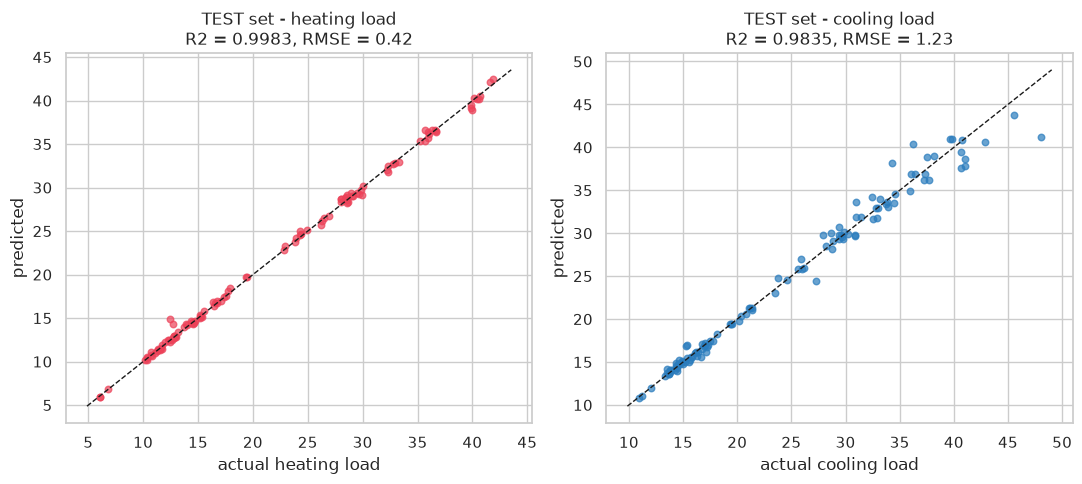

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, t in zip(axes, TARGETS):
    act, pred = test[t].values, preds[t]
    ax.scatter(act, pred, s=22, color=COLORS[t], alpha=0.7)
    lim = [min(act.min(), pred.min()) - 1, max(act.max(), pred.max()) + 1]; ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel(f"actual {t.replace('_', ' ')}"); ax.set_ylabel("predicted")
    ax.set_title(f"TEST set - {t.replace('_', ' ')}\nR2 = {r2_score(act, pred):.4f}, RMSE = {rmse(act, pred):.2f}")
save("16_test_predicted_vs_actual")
plt.show()

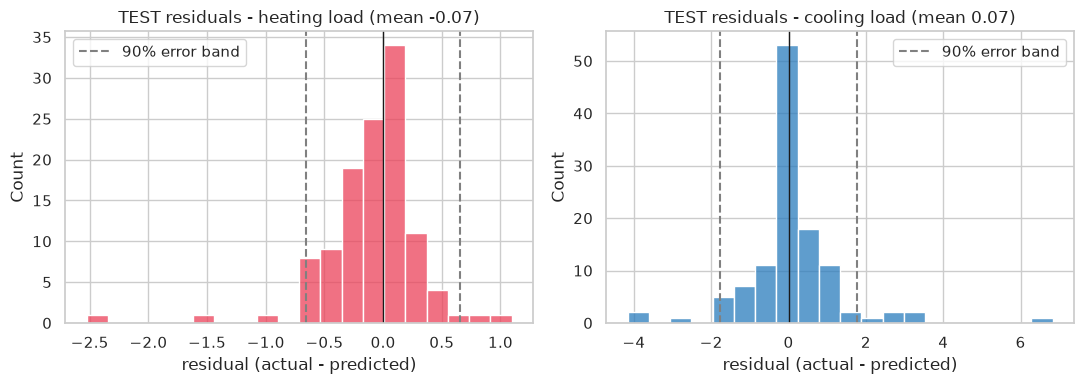

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t in zip(axes, TARGETS):
    resid = test[t].values - preds[t]
    sns.histplot(resid, bins=20, color=COLORS[t], ax=ax); ax.axvline(0, color="k", lw=1)
    ax.axvline(cfg[t]["error_band_90"], color="grey", ls="--"); ax.axvline(-cfg[t]["error_band_90"], color="grey", ls="--", label="90% error band")
    ax.set_xlabel("residual (actual - predicted)"); ax.set_title(f"TEST residuals - {t.replace('_', ' ')} (mean {resid.mean():.2f})"); ax.legend()
save("17_test_residuals")
plt.show()

### Validation vs. test: did the models generalise?
**Generalisation** = performing well on *new* data. If the test error is similar to the validation error, the models generalise.

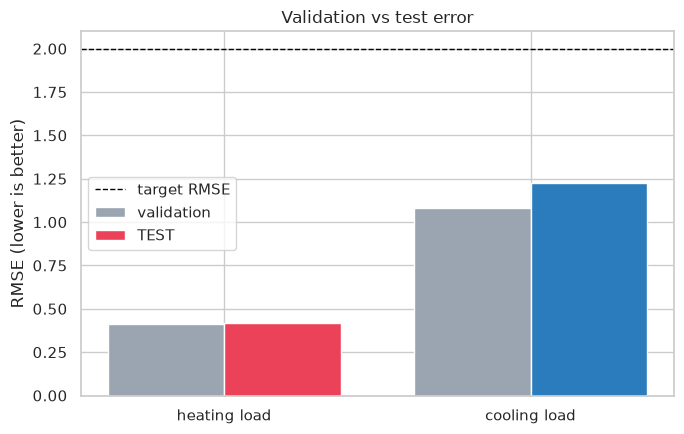

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(final)); w = 0.38
ax.bar(x - w/2, final["val_RMSE"], w, color="#9aa5b1", label="validation")
ax.bar(x + w/2, final["TEST_RMSE"], w, color=[COLORS[t] for t in final.target], label="TEST")
ax.axhline(TARGET_RMSE, color="black", ls="--", lw=1, label="target RMSE")
ax.set_xticks(x); ax.set_xticklabels([t.replace("_", " ") for t in final.target]); ax.set_ylabel("RMSE (lower is better)")
ax.set_title("Validation vs test error"); ax.legend()
save("18_validation_vs_test")
plt.show()

---
# Step 8.2 - Final stress test: shapes the models have never seen

The test set above contains the **same 12 shapes** as the training set (only the orientation/window combinations are new). A real architect with a brand-new design needs the harder question: *what if the shape itself is new?*

We answer it with **leave-one-shape-out** testing on **all 768 buildings**: for each of the 12 shapes, train on the other 11, predict the hidden one, and pool the results. (This is a final reporting step, not a model-selection step, so it uses the models' chosen settings without changing them.)

In Notebook 2 the simple **Ridge** model was the best at predicting unseen shapes. We therefore also evaluate it here as a **fallback** model for custom geometries, next to the accurate main model. (Honest note: we chose Ridge *because* it did well in the earlier leave-one-shape-out run on training and validation buildings, so its numbers here are slightly optimistic.)

In [6]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

def make_fallback(unfitted):
    """The simple fallback: same preprocessing, then a Ridge (penalised straight-line) model."""
    return Pipeline([("prep", clone(unfitted.named_steps["prep"])), ("model", Ridge(alpha=1.0))])

alld = pd.concat([train, val, test], ignore_index=True)
Xall, gall = alld[FEATS], alld["shape_id"]
unseen_rows, unseen_pred = [], {}
for t in TARGETS:
    main_est = lean(joblib.load(MODELS / f"{t}_unfitted.joblib"))
    base = np.zeros(len(alld))
    for role, est, label in [("main", main_est, cfg[t]["model"].split(" (")[0]), ("fallback", make_fallback(main_est), "Ridge")]:
        oof = np.zeros(len(alld))
        for tr_i, te_i in LeaveOneGroupOut().split(Xall, alld[t], gall):
            oof[te_i] = clone(est).fit(Xall.iloc[tr_i], alld[t].iloc[tr_i]).predict(Xall.iloc[te_i])
            if role == "main": base[te_i] = alld[t].iloc[tr_i].mean()
        unseen_pred[(t, role)] = oof
        unseen_rows.append({"target": t, "role": role, "model": label, "unseen_shape_RMSE": rmse(alld[t], oof),
                            "unseen_shape_MAE": mean_absolute_error(alld[t], oof), "unseen_shape_R2": r2_score(alld[t], oof)})
    for r in unseen_rows[-2:]: r["baseline_RMSE"] = rmse(alld[t], base)
unseen = pd.DataFrame(unseen_rows); unseen.round(3)

,target,role,model,unseen_shape_RMSE,unseen_shape_MAE,unseen_shape_R2,baseline_RMSE
0,heating_load,main,XGBoost,5.258,4.165,0.728,10.919
1,heating_load,fallback,Ridge,4.081,2.895,0.836,10.919
2,cooling_load,main,XGBoost,7.408,5.478,0.393,10.306
3,cooling_load,fallback,Ridge,4.599,3.398,0.766,10.306


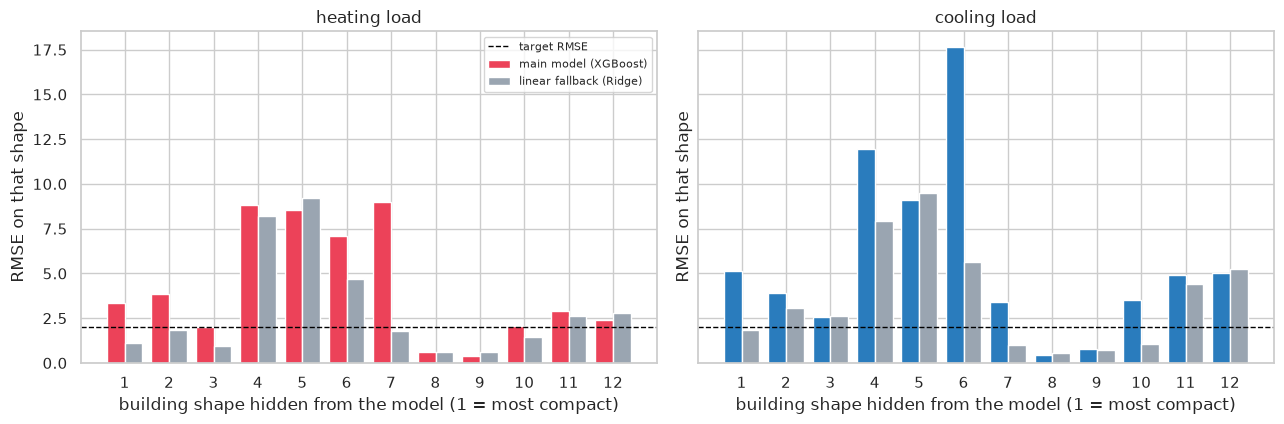

shape_id                1    2    3     4    5     6    7    8    9    10   11   12
main     heating_load  3.4  3.9  2.0   8.8  8.6   7.1  9.0  0.6  0.4  2.1  2.9  2.4
         cooling_load  5.1  3.9  2.6  11.9  9.1  17.6  3.4  0.5  0.8  3.5  4.9  5.0
fallback heating_load  1.1  1.8  1.0   8.2  9.2   4.7  1.8  0.6  0.6  1.4  2.6  2.8
         cooling_load  1.8  3.1  2.6   7.9  9.5   5.6  1.0  0.6  0.7  1.1  4.4  5.2

In [7]:
per_shape = {role: pd.DataFrame({t: [rmse(alld[t][gall == s], unseen_pred[(t, role)][gall == s]) for s in range(1, 13)] for t in TARGETS},
                                index=pd.Index(range(1, 13), name="shape_id")) for role in ["main", "fallback"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, t in zip(axes, TARGETS):
    x = np.arange(12); w = 0.4
    ax.bar(x - w/2, per_shape["main"][t], w, color=COLORS[t], label="main model (XGBoost)")
    ax.bar(x + w/2, per_shape["fallback"][t], w, color="#9aa5b1", label="linear fallback (Ridge)")
    ax.axhline(TARGET_RMSE, color="black", ls="--", lw=1, label="target RMSE")
    ax.set_xticks(x); ax.set_xticklabels(range(1, 13)); ax.set_xlabel("building shape hidden from the model (1 = most compact)")
    ax.set_title(f"{t.replace('_', ' ')}"); ax.set_ylabel("RMSE on that shape")
axes[0].legend(fontsize=8)
save("19_unseen_shape_final")
plt.show()
pd.concat({r: per_shape[r].round(1).T for r in per_shape})

---
# Step 8.3 - Preparing the models for deployment

### Retrain on train + validation
Evaluation is finished, so for the models that will actually be **used** we retrain the **same pipeline with the same settings** on **train + validation together** (more buildings usually means a slightly better model). We first run a **sanity check**: their predictions on the test buildings should be almost identical to the train-only models. These deployed models have never seen the test buildings either, so after building the bundle we can also measure them on the test set as one more check. We keep the train-only numbers above as our headline results, so that nothing is chosen after looking at the test set.

### An honest error band
Each prediction is shown with a **90% error band**: the size of error that 90% of out-of-sample predictions stay within, measured with 5-fold cross-validation on the training data used for the deployed model.

### Two models in the app: accurate for known shapes, a safe fallback for custom ones
The stress tests showed that the accurate model only works for the 12 known shapes. So the app uses **two models**: the **main model** when the user picks one of the 12 shapes, and a **simple linear fallback (Ridge)** when the user types a custom geometry, because the linear model was the most robust one on unseen shapes. The fallback has a much **wider error band**, measured by leave-one-shape-out cross-validation, and the app says clearly which model it used.

In [8]:
tv = pd.concat([train, val], ignore_index=True)
cv = KFold(5, shuffle=True, random_state=SEED)
bundle = {"features": FEATS}
for t in TARGETS:
    pipe = lean(joblib.load(MODELS / f"{t}_unfitted.joblib")).fit(tv[FEATS], tv[t])
    oof = cross_val_predict(clone(pipe), tv[FEATS], tv[t], cv=cv, n_jobs=1)     # XGBoost already uses all cores itself
    band = float(np.quantile(np.abs(tv[t].values - oof), 0.90))
    diff = np.abs(pipe.predict(test[FEATS]) - fitted[t].predict(test[FEATS]))
    row = final[final.target == t].iloc[0]
    u = unseen[(unseen.target == t) & (unseen.role == "main")].iloc[0]; uf = unseen[(unseen.target == t) & (unseen.role == "fallback")].iloc[0]
    print(f"{t:>13}: mean |difference| vs train-only model on test buildings = {diff.mean():.3f}, max = {diff.max():.3f} | 90% band = +/- {band:.2f}")

    # fallback for custom geometries: simple Ridge, with an error band measured by leave-one-shape-out on the same training data
    fb = make_fallback(joblib.load(MODELS / f"{t}_unfitted.joblib"))
    oof_fb = np.zeros(len(tv))
    for tr_i, te_i in LeaveOneGroupOut().split(tv[FEATS], tv[t], tv["shape_id"]):
        oof_fb[te_i] = clone(fb).fit(tv[FEATS].iloc[tr_i], tv[t].iloc[tr_i]).predict(tv[FEATS].iloc[te_i])
    fb_band = float(np.quantile(np.abs(tv[t].values - oof_fb), 0.90))
    print(f"{'':>13}  fallback (Ridge): 90% band for an unseen shape = +/- {fb_band:.2f}")
    bundle[t] = {"pipeline": pipe, "model_name": cfg[t]["model"], "error_band_90": band, "trained_on_rows": int(len(tv)),
                 "test_metrics": {"MAE": float(row.TEST_MAE), "RMSE": float(row.TEST_RMSE), "R2": float(row.TEST_R2),
                                  "RMSE_ci": row["RMSE_95%CI"], "R2_ci": row["R2_95%CI"], "baseline_RMSE": float(row.baseline_RMSE)},
                 "unseen_shape": {"RMSE": float(u.unseen_shape_RMSE), "R2": float(u.unseen_shape_R2), "baseline_RMSE": float(u.baseline_RMSE)},
                 "fallback": {"pipeline": fb.fit(tv[FEATS], tv[t]), "model_name": "Ridge (linear fallback)", "error_band_90": fb_band,
                              "unseen_shape": {"RMSE": float(uf.unseen_shape_RMSE), "R2": float(uf.unseen_shape_R2)}}}
joblib.dump(bundle, MODELS / "deploy_bundle.joblib")
print("Saved models/deploy_bundle.joblib (", round((MODELS / "deploy_bundle.joblib").stat().st_size / 1e6, 1), "MB )")

 heating_load: mean |difference| vs train-only model on test buildings = 0.123, max = 1.050 | 90% band = +/- 0.58


               fallback (Ridge): 90% band for an unseen shape = +/- 8.46


 cooling_load: mean |difference| vs train-only model on test buildings = 0.374, max = 4.281 | 90% band = +/- 1.59


               fallback (Ridge): 90% band for an unseen shape = +/- 6.76


Saved models/deploy_bundle.joblib ( 4.1 MB )


In [9]:
# The deployed models were trained on train + validation only, so the test buildings are still unseen for them.
dep = predict_loads(bundle, test[RAW])
chk = []
for t in TARGETS:
    err = test[t].values - dep[t].values
    chk.append({"target": t, "deployed RMSE on test": rmse(test[t], dep[t]), "deployed R2 on test": r2_score(test[t], dep[t]),
                "deployed 90% band": bundle[t]["error_band_90"], "test buildings inside the band": float((np.abs(err) <= bundle[t]["error_band_90"]).mean())})
pd.DataFrame(chk).round(4)

,target,deployed RMSE on test,deployed R2 on test,deployed 90% band,test buildings inside the band
0,heating_load,0.3398,0.9989,0.5816,0.9052
1,cooling_load,0.7373,0.9941,1.5906,0.9397


**Reading it:** the retrained models perform like the train-only ones, and the error bands that the app actually shows cover about the intended 90% of the test buildings.

### Checking the deployment code path
The app receives the **8 raw inputs** and must rebuild the **3 engineered features** itself (`inference.py`). A mismatch between training-time and deployment-time feature code is a classic silent bug (*training/serving skew*), so we verify that rebuilding them from the raw inputs reproduces the engineered columns exactly:

In [10]:
rebuilt = add_engineered(test[RAW])
print("Max difference vs training-time values:", max(float((rebuilt[c] - test[c]).abs().max()) for c in ENGINEERED))
out = predict_loads(bundle, test[RAW].head(5))
pd.concat([test[TARGETS].head(5).add_prefix("actual_").reset_index(drop=True), out.reset_index(drop=True).round(2)], axis=1)

Max difference vs training-time values: 0.0


,actual_heating_load,actual_cooling_load,heating_load,heating_load_band,cooling_load,cooling_load_band
0,28.93,28.20,29.410000,0.58,27.600000,1.59
1,17.05,23.77,16.990000,0.58,23.620001,1.59
2,22.79,28.79,22.820000,0.58,28.920000,1.59
3,28.57,29.69,28.559999,0.58,29.520000,1.59
4,11.70,13.88,11.520000,0.58,13.980000,1.59


### Information the web app needs
The app should let users **pick one of the 12 known building shapes** (rather than typing five numbers that must be consistent with each other), warn when they go **outside** what the models have seen, and show where a prediction sits among all the buildings in the data. We save the shape table, the allowed options and a reference sample (training + validation buildings only) in `models/app_assets.json` and `models/reference_sample.csv`.

In [11]:
shape_tbl = shapes[["shape_id", *GEOMETRY]].copy()
presets = {
    "Compact tall block, no windows": {"shape_id": 1, "orientation": 3, "glazing_area": 0.0, "glazing_area_distribution": 0},
    "Low-rise with large windows": {"shape_id": 10, "orientation": 4, "glazing_area": 0.4, "glazing_area_distribution": 1},
    "Tall building, medium windows": {"shape_id": 5, "orientation": 2, "glazing_area": 0.25, "glazing_area_distribution": 3},
}
assets = {
    "shapes": shape_tbl.to_dict("records"),
    "orientations": sorted(int(v) for v in tv.orientation.unique()),
    "glazing_areas": sorted(float(v) for v in tv.glazing_area.unique()),
    "glazing_distributions": sorted(int(v) for v in tv.glazing_area_distribution.unique()),
    "ranges": {c: [float(tv[c].min()), float(tv[c].max())] for c in GEOMETRY},
    "presets": presets,
}
json.dump(assets, open(MODELS / "app_assets.json", "w"), indent=1)
tv[RAW + TARGETS].to_csv(MODELS / "reference_sample.csv", index=False)
print("Saved models/app_assets.json and models/reference_sample.csv")

# do the preset designs give sensible answers?
rows = []
for name, p in presets.items():
    g = shape_tbl[shape_tbl.shape_id == p["shape_id"]].iloc[0]
    rows.append({"design": name, **{c: g[c] for c in GEOMETRY}, **{k: v for k, v in p.items() if k != "shape_id"}})
pre = pd.DataFrame(rows)
pd.concat([pre[["design"]], predict_loads(bundle, pre[RAW]).round(1)], axis=1)

Saved models/app_assets.json and models/reference_sample.csv


,design,heating_load,heating_load_band,cooling_load,cooling_load_band
0,"Compact tall block, no windows",15.900000,0.6,21.200001,1.6
1,Low-rise with large windows,15.300000,0.6,18.299999,1.6
2,"Tall building, medium windows",38.599998,0.6,45.200001,1.6


---
# Step 8.4 - Deployment with Streamlit

**What is deployment?** Making the models usable by people who do not run notebooks. We wrap them in a small web application built with **Streamlit** (a Python library that turns a script into a web page).

**The app (`app.py`) provides**
1. **Predict:** choose a building shape, orientation and windows, and get the predicted **heating and cooling load** with an error margin, how the design compares with the buildings in the data, and a *what-if* chart showing what happens when one input changes. A design can be **saved to a comparison list**. For a **custom geometry** the app switches to the linear fallback model, shows its wider error band and warns that the estimate is unreliable.
2. **Compare:** a table and chart of the saved designs, so options can be compared side by side.
3. **Model info:** accuracy on the test set (with intervals), including the honest *unseen shape* result, and the limits of the tool.
4. **Monitoring:** request counts, latency, drift checks, the share of requests outside the training range and, when users report real values, the live error.

**Run it locally (Docker):**
```
docker build -t ml-regression .
.\run_app.ps1
```
and open http://localhost:8501.

**Deploy for free in the cloud:** push the project folder to GitHub (`app.py`, `inference.py`, `monitor.py`, the `models` folder, `requirements.txt` and `.streamlit/config.toml`), then on **Streamlit Community Cloud** choose *New app*, select the repository, set the main file path to `Regression/app.py` and Python 3.11 under Advanced settings. Hugging Face Spaces and Render are alternatives. `requirements.txt` (the app's pinned list, which Streamlit Community Cloud installs) pins the exact library versions used for training, because a saved scikit-learn model must be loaded with the same version that created it.

> **Responsible use.** The models were trained on **simulated** buildings from a grid of only 12 shapes. They are a quick design-stage estimator, **not** a replacement for a proper energy simulation or measurements, and predictions for geometries far from the 12 shapes are unreliable (the app warns about this).

---
# Step 10 - Monitoring and Maintenance

A model's life does not end at deployment, because real conditions change. Our app supports five kinds of monitoring:

| What we watch | Why | Where |
|---|---|---|
| **Response latency** | Predictions should take milliseconds | Monitoring tab (mean, 95th percentile) |
| **Prediction levels** | A sudden change in the typical predicted loads signals that something changed | Monitoring tab |
| **Data drift** | If the designs entered differ from the training designs, the models may become unreliable | Monitoring tab + code below |
| **Out-of-domain rate** | Share of requests with a geometry that is **not** one of the 12 known shapes | Monitoring tab |
| **Live error** | Users can report the real (simulated or measured) loads, which lets us measure the true error over time | Feedback form + Monitoring tab |

**Retraining plan.** Retrain when drift is large for several inputs, when the live error clearly exceeds the validation/test error, when many requests fall outside the 12 known shapes (then add simulations of those shapes to the training data), or once a year. Retraining means re-running Notebooks 1-3 with the new data.

### The drift check
We use the **Population Stability Index (PSI)**, which compares the distribution of an input in the reference (training) data with new data. Rule of thumb: **PSI < 0.1 stable, 0.1-0.25 moderate shift, > 0.25 large shift.** Our inputs are mostly *discrete* (only 2 heights, 4 orientations ...), so for inputs with few distinct values we compare the **share of each value** (with a chi-square test), and for continuous ones the distribution (with a KS test). A shift is only reported when **both** the PSI and the significance test agree, and only after at least **100 logged requests**, because drift scores are very noisy on small samples (we learned this the hard way in the first project).

*Case 1 - normal:* the test buildings (the same population as the training data) should look stable.

In [12]:
ref = pd.read_csv(MODELS / "reference_sample.csv")
rep_ok = monitor.drift_report(ref, test[RAW], RAW)
print("Inputs flagged as shifted:", int((rep_ok.status != "stable").sum()), "of", len(rep_ok))
rep_ok

Inputs flagged as shifted: 1 of 8


,input,type,psi,p_value,status
0,orientation,categorical,0.102,0.0069,moderate shift
1,glazing_area_distribution,categorical,0.042,0.3699,stable
2,glazing_area,categorical,0.027,0.2817,stable
3,relative_compactness,categorical,0.003,1.0000,stable
4,surface_area,categorical,0.003,1.0000,stable
5,wall_area,categorical,0.001,1.0000,stable
6,roof_area,categorical,0.001,0.9924,stable
7,overall_height,categorical,0.000,1.0000,stable


*Case 2 - simulated drift:* we deliberately mimic a changed set of requests (most designs suddenly have 40% glazing and are tall) to prove the monitor notices:

In [13]:
rs = np.random.default_rng(SEED)
drifted = test[RAW].copy()
n = len(drifted); k = int(0.85 * n); pick = rs.choice(n, k, replace=False)
tall = shapes[shapes.overall_height == 7.0].reset_index(drop=True)
for j, i in enumerate(pick):
    g = tall.iloc[j % len(tall)]
    for c in GEOMETRY: drifted.iloc[i, drifted.columns.get_loc(c)] = g[c]
    drifted.iloc[i, drifted.columns.get_loc("glazing_area")] = 0.4
    drifted.iloc[i, drifted.columns.get_loc("glazing_area_distribution")] = int(rs.integers(1, 6))
rep_bad = monitor.drift_report(ref, drifted, RAW)
print("Inputs flagged as shifted:", int((rep_bad.status != "stable").sum()), "of", len(rep_bad))
rep_bad

Inputs flagged as shifted: 7 of 8


,input,type,psi,p_value,status
0,glazing_area,categorical,1.803,0.0000,LARGE shift
1,relative_compactness,categorical,1.506,0.0000,LARGE shift
2,surface_area,categorical,1.506,0.0000,LARGE shift
3,roof_area,categorical,1.123,0.0000,LARGE shift
4,overall_height,categorical,1.122,0.0000,LARGE shift
5,wall_area,categorical,0.976,0.0000,LARGE shift
6,orientation,categorical,0.102,0.0069,moderate shift
7,glazing_area_distribution,categorical,0.089,0.1498,stable


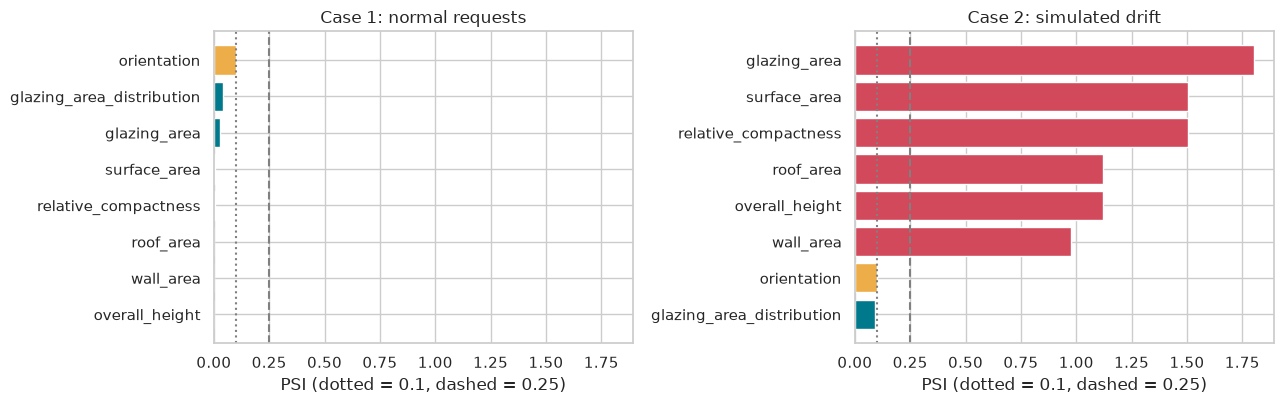

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, rep, title in zip(axes, [rep_ok, rep_bad], ["Case 1: normal requests", "Case 2: simulated drift"]):
    top = rep.sort_values("psi")
    ax.barh(top.input, top.psi, color=["#d1495b" if s == "LARGE shift" else "#edae49" if s == "moderate shift" else "#00798c" for s in top.status])
    ax.axvline(0.1, color="grey", ls=":"); ax.axvline(0.25, color="grey", ls="--")
    ax.set_title(title); ax.set_xlabel("PSI (dotted = 0.1, dashed = 0.25)")
save("20_drift_monitoring_demo")
plt.show()

*How often does the check cry wolf?* A monitor is only useful if it stays quiet when nothing has changed. We draw 300 random samples **from the reference population itself** (so there is truly no drift) and count how often the check still raises a flag. We repeat this for a small and a larger number of logged requests, which also shows why the app waits for at least 100 requests.

In [15]:
rs2 = np.random.default_rng(SEED)
calib = []
for n_rows in [30, 125]:
    any_flag = large = 0
    for _ in range(300):
        s = ref.sample(n_rows, replace=True, random_state=int(rs2.integers(1_000_000_000)))
        r = monitor.drift_report(ref, s, RAW)
        any_flag += bool((r.status != "stable").any()); large += bool((r.status == "LARGE shift").any())
    calib.append({"requests in the sample": n_rows, "runs with any flag": any_flag / 300, "runs with a LARGE flag": large / 300})
pd.DataFrame(calib).round(3)

,requests in the sample,runs with any flag,runs with a LARGE flag
0,30,0.230,0.057
1,125,0.113,0.003


**Reading it.** With 125 requests and *no* drift, the check raises a red **LARGE** alarm in only **0.3%** of runs (about 1 in 300) and a mild flag of any kind in about **11%** of runs, so a mild "moderate shift" flag now and then is just chance and not a reason to act. With only 30 requests the false **LARGE** alarm rate is **5.7%** (about 1 in 18) and mild flags appear in **23%** of runs. That is why the app waits for at least 100 logged requests before it shows a drift table.

**Result.**
* **Normal requests:** no input shows a *large* shift. One input, `orientation`, gets a mild **"moderate shift"** flag (PSI 0.10): the random test split happens to contain a slightly uneven mix of the four orientations (the full data has them perfectly balanced). With 8 inputs checked at once, one mild flag by chance is not surprising, and only a *large* shift raises the red alarm in the app.
* **Simulated drift:** the six inputs I deliberately changed (the geometry columns and the glazing area) are all flagged **LARGE**. The window distribution stays "stable" because I changed it randomly, and orientation shows the same mild flag as before.

So the same check, run in the app on logged requests, would warn us in real life.

---
# Summary of Notebook 3
* **Final test** of both models on unseen buildings, with confidence intervals and a comparison with validation.
* **Final unseen-shape stress test** on all 12 shapes, an honest measure for brand-new designs.
* **Deployment bundle** (`models/deploy_bundle.joblib`) retrained on train + validation, with a 90% error band, plus `app_assets.json` and `reference_sample.csv`.
* **Streamlit app** (`app.py`) with Predict, Compare, Model info and Monitoring tabs, prediction logging and a feedback form.
* **Monitoring & maintenance plan** with a working drift check.

**Next:** process documentation and the PowerPoint presentation.

---
# Glossary (new terms)
* **Generalisation:** how well a model performs on data it has never seen.
* **Bootstrap / confidence interval:** re-sampling the test set many times to see how much a score varies by chance.
* **Error band:** the size of error that a stated share (here 90%) of out-of-sample predictions stay within.
* **Training/serving skew:** the deployed system computing inputs differently from how training did.
* **Out of domain:** an input outside the range of the training data, where predictions are unreliable.
* **Latency:** how long one prediction takes.
* **Data drift:** the real-world data slowly changes compared with the training data.
* **PSI (Population Stability Index):** a number measuring how much an input's distribution has shifted.